# 第 08 步：我怎样把单期 IC 扩展成月度研究记录

<!-- SNAPSHOT_NOTE -->
## 我的数据准备说明

我在本页记录的是完整快照上的实际运行。如果我从 GitHub 克隆源码，我先在仓库根目录运行 `python publication/restore_snapshot.py`，恢复同版本的 `data/` 与 `runs/`，再执行本步。[完整数据与大型结果索引](../../publication/ASSET_INDEX.md)保留全部路径和哈希；本页图表与 Notebook 已保存输出可直接阅读。


## 我的目标与前置

我已经能够对 `2020-01-31` 的原始动量计算单期 Rank IC。本步我把同一套规则重复应用到 2020—2025 年的月末信号，分别检查平均 IC、时间波动、未年化 ICIR 和正 IC 月份占比。我关注关系的持续性，不从单个正值或负值推断因子必然有效。

我继续使用 40 只 SYN 模拟股票。历史输入覆盖 2019—2025 年，2019 年提供滚动窗口预热；正式研究区间来自 [baseline.json](../../configs/baseline.json)。本页的图表、均值和 ICIR 都不能成为真实 A 股因子有效性的证据。

我的前置是 [第 07 步的标签与 Rank IC](../07_forward_returns_rank_ic/README.md)。我在仓库根目录运行：

```powershell
# 我仅在环境尚未安装绘图库时安装一次绘图依赖。
.\.venv\Scripts\python.exe -m pip install -e ".[plots]"
.\.venv\Scripts\python.exe .\examples\08_monthly_ic.py
```

我使用的入口是 [08_monthly_ic.py](../../examples/08_monthly_ic.py)。我不需要先运行第 07 步脚本，因为本步会从同一输入重新计算原始动量和标签。

## 我先冻结时间划分

| 我的区间标识 | 我的用途 | 日期 |
|---|---|---|
| `development` | 我开发方法与解释指标的区间 | 2020-01-01 至 2022-12-31 |
| `validation` | 我检查规则是否能延续的区间 | 2023-01-01 至 2023-12-31 |
| `test` | 我报告冻结规则读数的最终区间 | 2024-01-01 至 2025-12-31 |

我按时间先后划分，不随机打乱月份。我保持动量正向、20 期回看和月度开盘到开盘标签，不依据测试期的正负修改方向。

我给每个月末保留一行记录，即使那个月不能完成有效检验。这样，研究表既记录结果，也记录无法计算的原因。

## 我怎样得到逐月 IC

我先取每月最后一个输入日历会话：

```python
month_ends = pd.Series(days, index=days).groupby(days.to_period("M")).last()
signal_dates = pd.DatetimeIndex(month_ends.to_numpy())
```

我用 `to_period("M")` 把日期映射到月份，再以 `last()` 取得该月末尾会话。这不是自然月最后一天，也不是假设真实 A 股每个工作日都开市；日期含义仍由这份模拟日历决定。

我对每个信号日构造同一时间结构：当前月末收盘信号 → 次会话开盘入场 → 下一月末之后的次会话开盘退出。未来收益在退出后才可知，因子仍然只读取信号日及以前的历史。

我要求信号、入场、退出都在同一时间分区内：

```python
begin, end = map(pd.Timestamp, config["splits"][split])
if not begin <= signal_date <= entry_date <= exit_date <= end:
    record["status"] = "cross_split"
```

我特别注意这个条件包含三种日期。只检查信号日属于开发期并不够：一个开发期信号可能在验证期开盘入场，也可能持有至验证期才退出。

我对通过时间检查的月份，继续按代码关联股票，去掉无效配对，然后以平均秩计算相关。有效配对不足 5 只或排序变量为常数时，我不报告有效 IC。

## 我怎样理解平均值、标准差和 ICIR

我令有效月数为 \(T\)，有效月度 IC 为 \(IC_t\)：

$$\overline{IC}=\frac1T\sum_{t=1}^{T}IC_t,$$

$$s_{IC}=\sqrt{\frac{\sum_t(IC_t-\overline{IC})^2}{T-1}},\qquad ICIR=\overline{IC}/s_{IC}.$$

我在代码中明确使用样本标准差 `ddof=1`：

```python
values = ic_table.loc[ic_table["split"] == split, "ic"].dropna()
mean_ic = values.mean()
ic_std = values.std(ddof=1)
icir = mean_ic / ic_std if ic_std > 0 else float("nan")
```

我用 `dropna()` 把无法检验的月份排除在分母之外，不把它们补成零 IC。标准差为零时，比例没有可报告的稳定有限值，所以保留缺失。

我本项目的 ICIR **没有年化**，没有乘以 \(\sqrt{12}\)，也不是策略夏普比率。平均 IC 描述关系的总体方向；标准差描述月度关系的波动；ICIR 把两者作一个描述性比值。它没有自行完成显著性检验。

## 我核实的月份排除记录

我在 2020—2025 年共有 72 个信号月，得到 66 个有效 IC。其余六个月不是“表现为零”，而是按照明确规则无法纳入。

| 我保留的信号日 | 入场 | 退出 | 状态 |
|---|---|---|---|
| 2022-11-30 | 2022-12-01 | 2023-01-02 | `cross_split` |
| 2022-12-30 | 2023-01-02 | 2023-02-01 | `cross_split` |
| 2023-11-30 | 2023-12-01 | 2024-01-01 | `cross_split` |
| 2023-12-29 | 2024-01-01 | 2024-02-01 | `cross_split` |
| 2025-11-28 | 2025-12-01 | 缺失 | `incomplete_exit` |
| 2025-12-31 | 缺失 | 缺失 | `incomplete_entry` |

我看到分界前的 11 月也会被排除，因为它的退出日落入下一分区。2025 年 11 月虽然能够入场，但缺少 12 月末之后的退出开盘；12 月末连下一执行日都没有。我没有追加虚构的未来价格。

## 我核对到的实际汇总

我从 [ic_summary.csv](../../runs/first_demo_20261107/lesson08_monthly_ic/ic_summary.csv) 核对以下数值：

| 区间 | 有效月数 | 平均 IC | IC 样本标准差 | 未年化 ICIR | 正 IC 月数 |
|---|---:|---:|---:|---:|---:|
| 开发期 | 34 | -0.0075046904 | 0.1636118680 | -0.0458688634 | 18 |
| 验证期 | 10 | 0.0763039400 | 0.1146196980 | 0.6657140204 | 7 |
| 测试期 | 22 | 0.0507845813 | 0.1683699639 | 0.3016249460 | 15 |

我把开发期的 `18/34 = 52.94%` 解释为正 IC 月份占比，不能称为交易胜率。开发期虽然超过一半月份为正，平均 IC 仍略为负，因为正负幅度也影响平均值。

我再看 [annual_ic_summary.csv](../../runs/first_demo_20261107/lesson08_monthly_ic/annual_ic_summary.csv)：

| 我按信号年份分组 | 有效月数 | 平均 IC |
|---|---:|---:|
| 2020 | 12 | -0.0299405879 |
| 2021 | 12 | -0.0118667917 |
| 2022 | 10 | 0.0246529081 |
| 2023 | 10 | 0.0763039400 |
| 2024 | 12 | 0.0042995622 |
| 2025 | 10 | 0.1065666041 |

我看到测试期平均数约为 `0.0508`，但 2024 年接近零，2025 年较高。我因此不能把整段均值等同于每年都稳定有效。这里的年份按信号日期归类，也不是股票组合的年度收益。

## 我怎样阅读图表

![我保存的RAW原始动量月度IC与分区均值](../../runs/first_demo_20261107/lesson08_monthly_ic/monthly_ic.png)

我把蓝色点线看作各月事后 IC，把灰色水平线看作零关系参照，把橙色虚线看作分区平均。空缺月份保留断点，不连成补零后的观测。浅色区域标记验证期，不表示额外的数据权重。

我先看均值相对零的位置，再看极端负值和正值的频率、幅度与时期分布。稳定地接近零只是“关系稳定地弱”，不自动成为有用的预测信号。

## 我的输出字段与复核路线

我在手工复核时，先从月度表筛出一个分区的有效值，数清行数，再计算这些相关系数的算术平均。我不会把每个月的四十只股票当成四十个月份：平均 IC 的时间样本量是有效月份数，验证期在本例中只有十个这样的观察。每期横截面的股票数量与跨期稳定性的时间长度，是两个不同维度。

我也不会仅根据十个验证月的较高比值就断言关系可靠。相邻月份可能受到共同环境影响，重复尝试不同窗口、方向和区间也会增加偶然发现的机会。即使以后加入时间相关调整，我仍然需要记录尝试过哪些规则，而不是只展示最漂亮的一套。我的当前表格保留固定方向与固定分界，便于以后追查这些选择。

我已经在这套教程里多次查看模拟测试期，它因此是用于理解方法的冻结基线读数，不是假装从未见过的真实市场独立检验。若我以后开展正式实证研究，我会在开发和验证阶段确定方法，再使用另外保留的数据或后续新数据评价冻结规则。我把这一点写入记录，是为了让代码里的区间名称与实际研究过程保持一致。

| 文件或字段 | 我的用途 |
|---|---|
| [monthly_ic.csv](../../runs/first_demo_20261107/lesson08_monthly_ic/monthly_ic.csv) | 我保留全部 72 个信号、时间点、配对数和状态 |
| `ic` | 我记录有效月份的秩相关，无效月份留空 |
| `n` | 我记录有效配对股票数；时间检查失败的月份为 0 |
| `status` | 我区分正常、跨区、缺入场、缺退出或统计条件不足 |
| `positive_share` | 我记录正 IC 月份占比，不记录盈亏胜率 |
| [ic_summary.csv](../../runs/first_demo_20261107/lesson08_monthly_ic/ic_summary.csv) | 我逐分区核对平均值、标准差和 ICIR |

## 我记录的常见错误与本步验收

- 我若把 72 当作所有均值的分母，就会把排除月份当作观测；我实际只对有效 IC 统计。
- 我若将 RAW 结果与参考模块 `z_momentum` 混为一谈，就会忽略 MAD 截断产生的并列排名。纯正向线性标准化保留秩，但截断可能改变秩相关。
- 我若把 ICIR 较大直接写成显著，就会漏掉小样本、时间相关和多次试验的问题。后续可以研究 HAC 等方法，本步不声称已完成这些推断。
- 我若看过测试结果后反转动量方向，再用同一测试区间证明有效，就会污染最终检验。

我验收时核对 `72 = 66 + 4 + 1 + 1`，核对开发/验证/测试有效月数为 34/10/22，核对首期 IC 与第 07 步一致，并确认没有把缺失补零或把 ICIR 年化。

我本步建立了可审计的月度因子研究记录。模拟样本显示关系随时期变化，平均数和正值占比都不足以单独说明可靠预测能力；下一步我改用分组收益，从另一个角度观察排名与未来收益的结构。

## 我的完整可运行实现

上面的片段用于解释思路；下面各单元按顺序执行完整脚本。我先定位仓库根目录，并显式设置脚本路径，使 `__file__` 在 Notebook 中也有明确含义。

In [1]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = next((candidate for candidate in [Path.cwd(), *Path.cwd().parents]
                     if (candidate / "pyproject.toml").exists()
                     and (candidate / "examples/01_read_prices.py").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("我需要从本项目目录或它的子目录打开 Notebook。")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.chdir(PROJECT_ROOT)
__file__ = str(PROJECT_ROOT / 'examples/08_monthly_ic.py')
sys.argv = [__file__]


### 完整实现 · 单元 1

In [2]:
"""第八课：原始动量的月度 Rank IC、平均 IC、未年化 ICIR；模拟数据。"""

from pathlib import Path
import pandas as pd
import matplotlib
from ashare_lab.config import load_config

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

project_dir = Path(__file__).resolve().parents[1]
data_path = project_dir / "runs" / "first_demo_20261107" / "input" / "prices.csv"
prices = pd.read_csv(data_path, dtype={"symbol": "string"}, parse_dates=["date"])
calendar = pd.read_csv(data_path.with_name("calendar.csv"), parse_dates=["date"])
days = pd.DatetimeIndex(calendar["date"])
config = load_config(project_dir / "configs" / "baseline.json")
lookback = config["lookback"]

# 1. 复用前两课：每只股票单独计算过去 20 个交易区间的原始动量。
factor_tables = []
for symbol, stock in prices.groupby("symbol", sort=True):
    stock = stock.sort_values("date").set_index("date").reindex(days).reset_index()
    stock["symbol"] = symbol
    close = stock["adj_close"].where(stock["adj_close"] > 0)
    count = close.rolling(lookback + 1, min_periods=lookback + 1).count()
    stock["momentum_20"] = (close / close.shift(lookback) - 1).where(count == lookback + 1)
    factor_tables.append(stock[["date", "symbol", "momentum_20"]])
factor_values = pd.concat(factor_tables, ignore_index=True)

# 2. 取每个月的最后一个模拟交易日，保留末尾不完整月份以便记录原因。
month_ends = pd.Series(days, index=days).groupby(days.to_period("M")).last()
signal_dates = pd.DatetimeIndex(month_ends.to_numpy())

### 完整实现 · 单元 2

In [3]:
def next_session(date):
    """没有下一交易日时返回缺失日期，不制造未来价格。"""
    if pd.isna(date):
        return pd.NaT
    position = days.get_loc(date)
    return days[position + 1] if position + 1 < len(days) else pd.NaT

### 完整实现 · 单元 3

In [4]:
# 3. 每个信号日重复上一课的标签、配对、排名和相关计算。
records = []
for i, signal_date in enumerate(signal_dates):
    if not pd.Timestamp(config["start"]) <= signal_date <= pd.Timestamp(config["end"]):
        continue
    split = next((name for name, bounds in config["splits"].items()
                  if pd.Timestamp(bounds[0]) <= signal_date <= pd.Timestamp(bounds[1])), None)
    next_signal = signal_dates[i + 1] if i + 1 < len(signal_dates) else pd.NaT
    entry_date = next_session(signal_date)
    exit_date = next_session(next_signal)
    record = dict(date=signal_date, entry_date=entry_date, exit_date=exit_date,
                  split=split, ic=float("nan"), n=0, status="ok")

    # 4. 不完整的持有期、跨样本分界的标签保留空 IC，并记录原因。
    if pd.isna(entry_date):
        record["status"] = "incomplete_entry"
    elif pd.isna(exit_date):
        record["status"] = "incomplete_exit"
    elif split is None:
        record["status"] = "outside_split"
    else:
        begin, end = map(pd.Timestamp, config["splits"][split])
        if not begin <= signal_date <= entry_date <= exit_date <= end:
            record["status"] = "cross_split"

    if record["status"] != "ok":
        records.append(record)
        continue

    snapshot = factor_values.loc[factor_values["date"] == signal_date].copy()
    entry = prices.loc[prices["date"] == entry_date, ["symbol", "adj_open"]].rename(
        columns={"adj_open": "entry_open"})
    exit_ = prices.loc[prices["date"] == exit_date, ["symbol", "adj_open"]].rename(
        columns={"adj_open": "exit_open"})
    paired = snapshot.merge(entry, on="symbol", how="left", validate="one_to_one")
    paired = paired.merge(exit_, on="symbol", how="left", validate="one_to_one")
    paired = paired.dropna(subset=["momentum_20", "entry_open", "exit_open"]).copy()
    paired = paired.loc[(paired["entry_open"] > 0) & (paired["exit_open"] > 0)].copy()
    paired["forward_return"] = paired["exit_open"] / paired["entry_open"] - 1
    record["n"] = len(paired)
    if len(paired) < 5:
        record["status"] = "insufficient_pairs"
    elif paired["momentum_20"].nunique() < 2 or paired["forward_return"].nunique() < 2:
        record["status"] = "constant_rank"
    else:
        factor_rank = paired["momentum_20"].rank(method="average", ascending=False)
        return_rank = paired["forward_return"].rank(method="average", ascending=False)
        record["ic"] = factor_rank.corr(return_rank)
    records.append(record)

### 完整实现 · 单元 4

In [5]:
ic_table = pd.DataFrame(records).sort_values("date").reset_index(drop=True)

# 5. 每个样本区间分别统计；分母只包含有效 IC，不把缺失值补零。
summary_records = []
for split in config["splits"]:
    values = ic_table.loc[ic_table["split"] == split, "ic"].dropna()
    mean_ic = values.mean()
    ic_std = values.std(ddof=1)
    icir = mean_ic / ic_std if ic_std > 0 else float("nan")
    summary_records.append(dict(
        split=split, n_months=len(values), mean_ic=mean_ic, ic_std=ic_std, icir=icir,
        positive_months=int((values > 0).sum()), positive_share=(values > 0).mean(),
    ))
summary = pd.DataFrame(summary_records)

# 6. 按信号年份检查均值，观察整段平均数是否掩盖时期差异。
annual_summary = ic_table.groupby(ic_table["date"].dt.year)["ic"].agg(
    n_months="count", mean_ic="mean", ic_std="std",
).reset_index().rename(columns={"date": "signal_year"})

# 7. 保存本课的可核对结果；完整表保留全部月份和排除原因。
output_dir = data_path.parent.parent / "lesson08_monthly_ic"
output_dir.mkdir(parents=True, exist_ok=True)
ic_table.to_csv(output_dir / "monthly_ic.csv", index=False, date_format="%Y-%m-%d")
summary.to_csv(output_dir / "ic_summary.csv", index=False)
annual_summary.to_csv(output_dir / "annual_ic_summary.csv", index=False)

# 8. 绘制完整月度序列：NaN 月份自然断开，虚线为各样本区间的平均 IC。
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.size"] = 11
fig, ax = plt.subplots(figsize=(11.5, 5.8), layout="constrained")
ax.plot(ic_table["date"], ic_table["ic"], color="#3268A8", linewidth=1.3,
        marker="o", markersize=3.3, label="每月 Rank IC")
ax.axhline(0, color="#747D86", linewidth=1.0, label="零线")
valid_ic = ic_table["ic"].dropna()
lower = min(-0.4, valid_ic.min() - 0.12)
upper = max(0.4, valid_ic.max() + 0.10)
ax.set_ylim(lower, upper)
split_labels = {"development": "开发期", "validation": "验证期", "test": "测试期"}
for index, (split, bounds) in enumerate(config["splits"].items()):
    block = ic_table.loc[ic_table["split"] == split]
    if block.empty:
        continue
    mean = summary.loc[summary["split"] == split, "mean_ic"].iloc[0]
    ax.hlines(mean, block["date"].min(), block["date"].max(), color="#B46A31",
              linewidth=1.5, linestyle="--", label="分区平均 IC" if index == 0 else None)
    begin, end = map(pd.Timestamp, bounds)
    if index > 0:
        ax.axvline(begin, color="#AEB7BF", linewidth=0.8, linestyle=":")
    if split == "validation":
        ax.axvspan(begin, end, color="#747D86", alpha=0.06)
    ax.text(begin + (end - begin) / 2, lower + (upper - lower) * 0.035,
            split_labels.get(split, split), ha="center", va="bottom", color="#59636D")

### 完整实现 · 单元 5

In [6]:
tick_indices = sorted({0, len(ic_table) // 3, len(ic_table) * 2 // 3, len(ic_table) - 1})
ax.set_xticks(ic_table["date"].iloc[tick_indices])
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.set_xlim(ic_table["date"].iloc[0], ic_table["date"].iloc[-1])
ax.set_title("原始20日动量：月度 Rank IC（模拟数据）", fontsize=16, pad=15)
ax.set_ylabel("Rank IC（无量纲）")
ax.set_xlabel("信号月份（IC 为事后统计；不完整或跨区间月份留空）")
ax.legend(loc="upper left", frameon=False, fontsize=10, ncols=3)
ax.grid(axis="y", color="#DCE2E8", linewidth=0.7)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#B5BDC5")
fig.savefig(output_dir / "monthly_ic.png", dpi=180)
plt.close(fig)

print("模拟数据；原始动量；月度理论开盘到开盘标签；ICIR 未年化。")
print("\n前 12 个信号月：")
print(ic_table.head(12).to_string(index=False))
print("\n分区汇总（positive_share 为正 IC 月份占比，不是交易胜率）：")
print(summary.to_string(index=False, formatters={"positive_share": "{:.2%}".format}))
print("\n按信号年份汇总：")
print(annual_summary.to_string(index=False))
print("\n月份状态计数：")
print(ic_table["status"].value_counts().to_string())
print("\n结果目录：", output_dir)

模拟数据；原始动量；月度理论开盘到开盘标签；ICIR 未年化。

前 12 个信号月：
      date entry_date  exit_date       split        ic  n status
2020-01-31 2020-02-03 2020-03-02 development -0.117073 40     ok
2020-02-28 2020-03-02 2020-04-01 development -0.047467 40     ok
2020-03-31 2020-04-01 2020-05-01 development -0.135647 40     ok
2020-04-30 2020-05-01 2020-06-01 development -0.283302 40     ok
2020-05-29 2020-06-01 2020-07-01 development  0.028143 40     ok
2020-06-30 2020-07-01 2020-08-03 development -0.335647 40     ok
2020-07-31 2020-08-03 2020-09-01 development  0.011069 40     ok
2020-08-31 2020-09-01 2020-10-01 development  0.129644 40     ok
2020-09-30 2020-10-01 2020-11-02 development  0.145966 40     ok
2020-10-30 2020-11-02 2020-12-01 development  0.236773 40     ok
2020-11-30 2020-12-01 2021-01-01 development  0.137336 40     ok
2020-12-31 2021-01-01 2021-02-01 development -0.129081 40     ok

分区汇总（positive_share 为正 IC 月份占比，不是交易胜率）：
      split  n_months   mean_ic   ic_std      icir  positive_months po

## 我的图表输出

完整脚本已经保存图表。我在这里把本步或正文明确引用的跨步图表显示为静态输出，因此 GitHub 页面无需活动内核也能看到图片。数值与图表来源沿用正文说明。

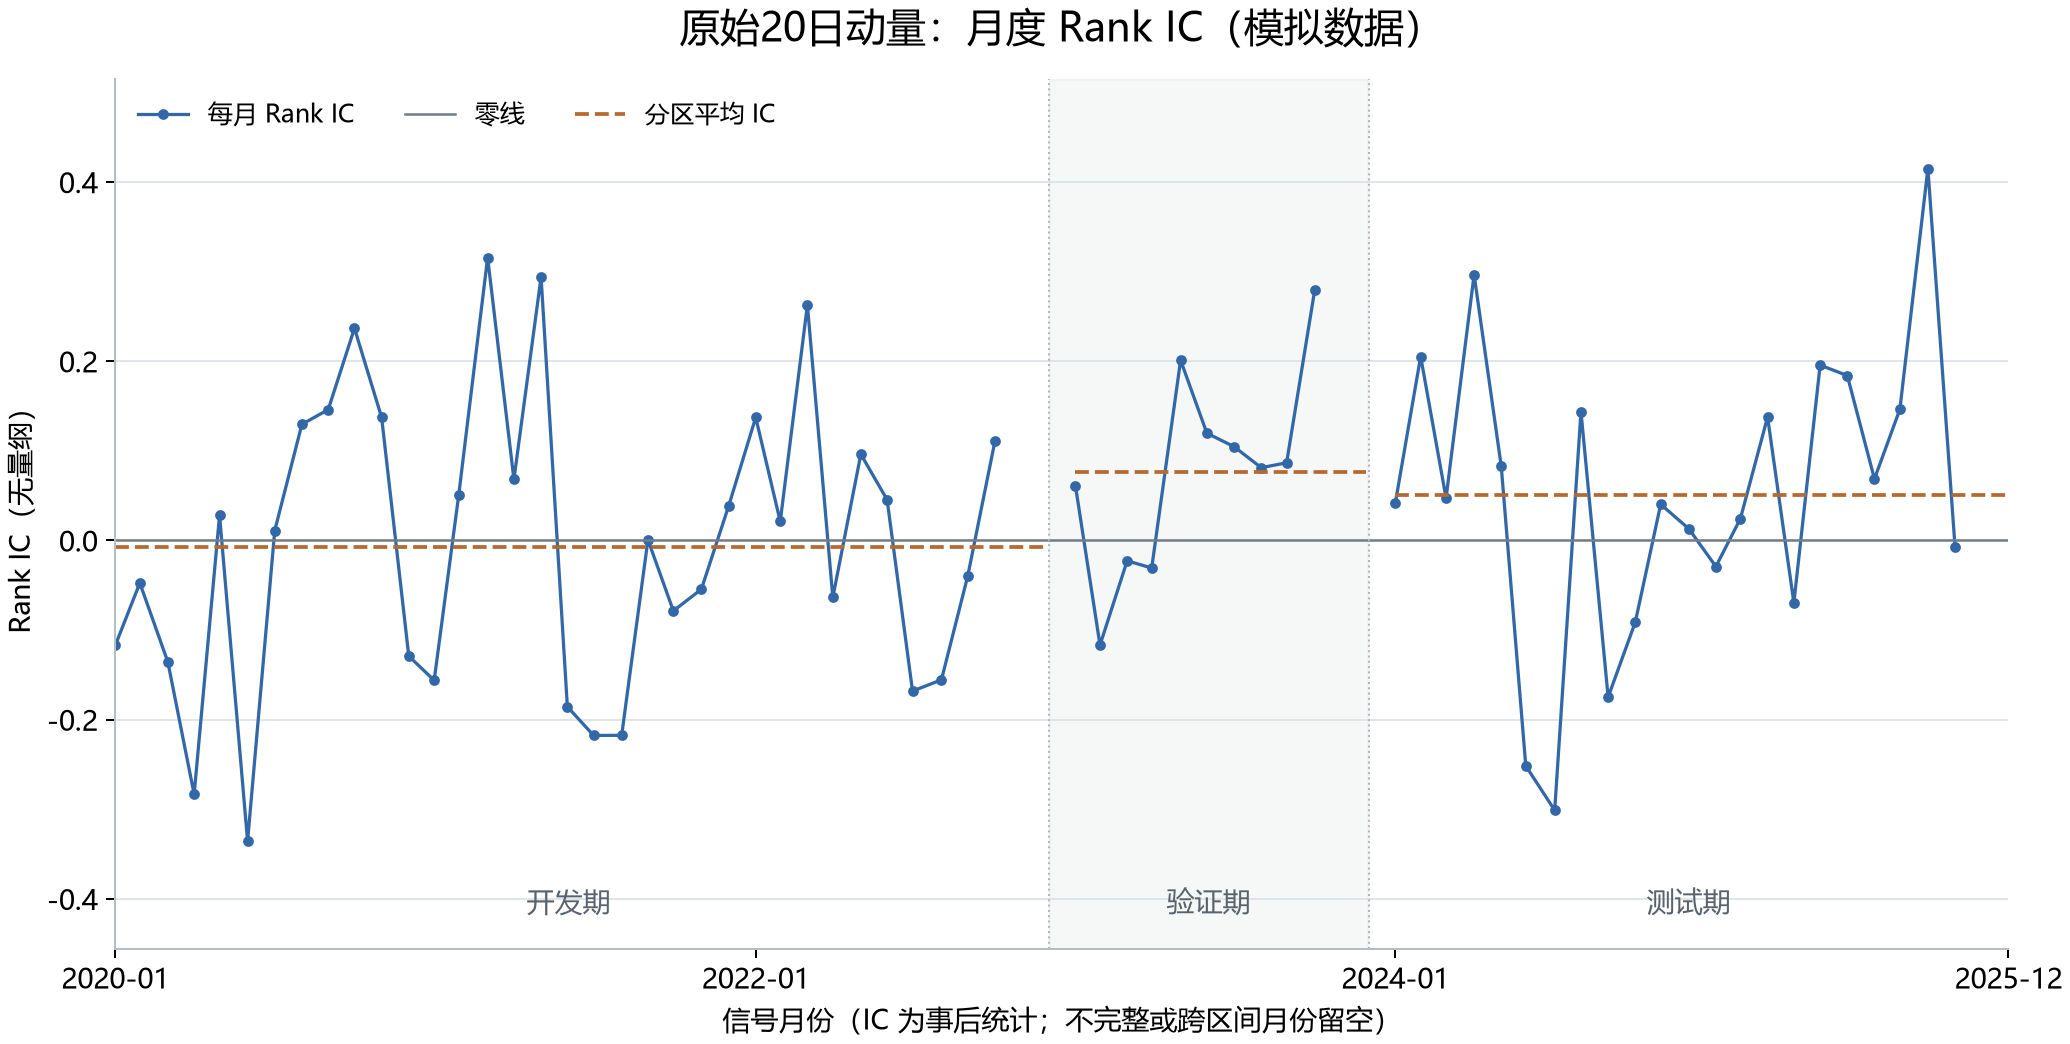

In [7]:
from IPython.display import Image, display
display(Image(filename=str(PROJECT_ROOT / 'runs/first_demo_20261107/lesson08_monthly_ic/monthly_ic.png')))

## 我的复核

我在干净内核中按顺序执行以上实现；执行状态记录在仓库的 [Notebook 校验记录](../../publication/notebook_validation.json)。代码中的数据身份、费用和成交假设仍然适用，运行成功只验证对应实现。